In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## scaling-law

**Test loss of Transformer language models on WebText2 against model size.** Both axes are on a log scale; circles show models trained to near convergence, and the dashed line is the power-law fit L = (N / 8.8·10¹³)^−0.076, with N the number of non-embedding parameters. Loss falls as a power law over six orders of magnitude, from 5.95 at 6K parameters to 2.35 at 1.5B, with no sign of deviation at the largest models.

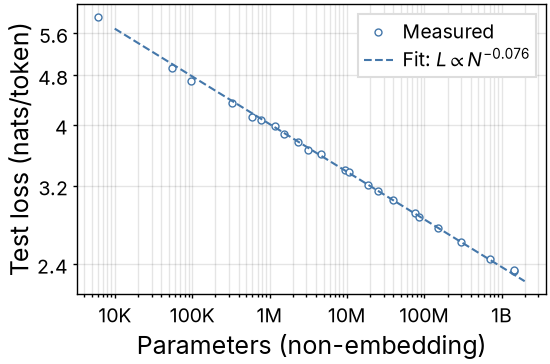

In [2]:
from matplotlib.ticker import NullFormatter

data = json.load(open("../data/scaling-law.json"))
n = np.array(data["non_embedding_parameters"])
loss = np.array(data["test_loss"])
n_c, alpha = data["fit"]["N_c"], data["fit"]["alpha_N"]
n_fit = np.geomspace(*data["fit"]["plotted_N_range"], 200)

fig, ax = plt.subplots(figsize=(2.75, 2))
ax.plot(n, loss, "o", color=colors["series-1"], label="Measured")
ax.plot(n_fit, (n_fit / n_c) ** -alpha, linestyle="--", linewidth=paper.dashed_width, color=colors["series-1"],
        label=f"Fit: $L \\propto N^{{-{alpha}}}$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1e4, 1e5, 1e6, 1e7, 1e8, 1e9], labels=["10K", "100K", "1M", "10M", "100M", "1B"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.grid(True, which="both")
ax.set_yticks([2.4, 3.2, 4.0, 4.8, 5.6], labels=["2.4", "3.2", "4", "4.8", "5.6"])
ax.set_yticks([], minor=True)
ax.set_xlabel("Parameters (non-embedding)")
ax.set_ylabel("Test loss (nats/token)")
ax.legend(loc="upper right")
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/scaling-law.pdf")
fig.savefig("../outputs/scaling-law.png")
plt.show()